# Pescadores Web — onde o cadastro de OSCs não oferece parceiros?
**Autor: Felipe Barbosa Vieira** — Turma SI 7/8 Noturno · Ciência de Dados e Aprendizado de Máquina · Profa. Kadidja Valéria · UDF · 2026.2

Atividade 07 do Módulo IV: aplicar o fluxo supervisionado da Aula 2 (holdout estratificado, validação cruzada no treino, árvore de decisão, referência `DummyClassifier`, matriz de confusão) ao contexto do meu TCC, o **Pescadores Web** (com Calebe Mendes Bezerra).

**Dados reais, sem registros inventados.** O Pescadores Web ainda não tem dados operacionais (doações, estoque, voluntários). Por isso uso a tabela municipal já preparada no meu [projeto de ciência de dados](https://github.com/lipefe11/Ciencia_Dados_Aprendizagem_Maquina/tree/main/Projeto_ciencia_de_dados): contagem de OSCs de assistência social **ativas** no Mapa das OSCs (Ipea, arquivo 20260806) por município, cruzada com a população do Censo 2022 (IBGE, SIDRA 4714). Procedência, filtros e hashes estão em `Projeto_ciencia_de_dados/dados/brutos/FONTES.json`.

**Pergunta.** Só com o porte populacional e a região, dá para reconhecer os municípios que **não têm nenhuma** OSC de assistência social ativa no cadastro? Isso é diferente do que o projeto já fez (regressão do número de OSCs e classificação da situação cadastral de cada OSC): aqui a unidade é o município e o alvo é binário.

In [1]:
import os, sys, json
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import sklearn
from sklearn.model_selection import (train_test_split, StratifiedKFold, GroupKFold, cross_validate)
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, confusion_matrix, ConfusionMatrixDisplay,
                             precision_score, recall_score, f1_score, make_scorer)
SEMENTE = 42
PASTA_ASSETS = '../assets' if os.path.isdir('../assets') else './assets'
os.makedirs(PASTA_ASSETS, exist_ok=True)
def salvar(nome):
    caminho = os.path.join(PASTA_ASSETS, nome)
    plt.savefig(caminho, dpi=120, bbox_inches='tight')
    print('figura gravada:', caminho)
print('Python:', sys.version.split()[0], '| NumPy:', np.__version__, '| pandas:', pd.__version__,
      '| matplotlib:', matplotlib.__version__, '| scikit-learn:', sklearn.__version__)

Python: 3.13.18 | NumPy: 2.5.3 | pandas: 3.0.5 | matplotlib: 3.11.2 | scikit-learn: 1.9.1


## 1. Leitura dos dados (com caminhos alternativos)
Ordem de tentativa: cópia em `../dados/` desta pasta → arquivo original do projeto no mesmo repositório → arquivos no GitHub (para o Colab).

In [2]:
RAIZ_RAW = 'https://raw.githubusercontent.com/lipefe11/Ciencia_Dados_Aprendizagem_Maquina/main/'
FONTES = ['../dados/municipios_oscs_assistencia.csv',
          '../../../Projeto_ciencia_de_dados/dados/tratados/municipios.csv',
          RAIZ_RAW + 'Aprendizado_de_Maquina/Aprendizado%20de%20m%C3%A1quina/dados/municipios_oscs_assistencia.csv',
          RAIZ_RAW + 'Projeto_ciencia_de_dados/dados/tratados/municipios.csv']
COLUNAS = ['cd_municipio', 'municipio', 'uf', 'populacao_2022', 'oscs_ativas']
mun = None
for fonte in FONTES:
    try:
        mun = pd.read_csv(fonte)[COLUNAS]
        print('lido de:', fonte)
        break
    except Exception as erro:
        print('indisponível:', fonte, '-', type(erro).__name__)
assert mun is not None, 'nenhuma fonte de dados disponível'

print('Municípios:', len(mun), '| UFs:', mun['uf'].nunique())
print('Total de OSCs ativas somadas:', int(mun['oscs_ativas'].sum()))
print(mun.describe().round(1).to_string())

lido de: ../dados/municipios_oscs_assistencia.csv
Municípios: 5570 | UFs: 27
Total de OSCs ativas somadas: 39836
       cd_municipio  populacao_2022  oscs_ativas
count        5570.0          5570.0       5570.0
mean      3253590.8         36459.7          7.2
std        984910.3        206518.7         47.1
min       1100015.0           833.0          0.0
25%       2512125.8          5228.0          0.0
50%       3146280.0         11065.0          2.0
75%       4119189.5         24427.2          5.0
max       5300108.0      11451999.0       2895.0


## 2. Alvo, atributos e o que fica de fora
- **Unidade de análise:** município (5.570 do Censo 2022).
- **Alvo:** `sem_osc_ativa` = 1 quando o município tem **zero** OSCs de assistência social ativas no recorte; 0 caso contrário.
- **Atributos:** `log10_pop` (população 2022 em escala log) e `regiao` (1º dígito do código IBGE: 1 Norte, 2 Nordeste, 3 Sudeste, 4 Sul, 5 Centro-Oeste), em variáveis indicadoras.
- **Fora dos atributos:** `oscs_ativas`, `oscs_por_100mil`, idade mediana e fração recente das OSCs — todos derivados das próprias OSCs e, portanto, revelariam o alvo (vazamento).

In [3]:
NOMES_REGIAO = {1: 'Norte', 2: 'Nordeste', 3: 'Sudeste', 4: 'Sul', 5: 'Centro-Oeste'}
mun['sem_osc_ativa'] = (mun['oscs_ativas'] == 0).astype(int)
mun['log10_pop'] = np.log10(mun['populacao_2022'])
mun['regiao'] = (mun['cd_municipio'] // 1_000_000).map(NOMES_REGIAO)
print('Proporção sem OSC ativa: %.3f (%d de %d)' % (mun['sem_osc_ativa'].mean(),
      mun['sem_osc_ativa'].sum(), len(mun)))

faixas = pd.cut(mun['populacao_2022'], [0, 5_000, 10_000, 20_000, 50_000, 100_000, 1e8],
                labels=['até 5 mil', '5–10 mil', '10–20 mil', '20–50 mil', '50–100 mil', 'acima de 100 mil'])
print('\nPor porte (base inteira, só descritivo):')
print(mun.groupby(faixas, observed=True)['sem_osc_ativa'].agg(['mean', 'size']).round(3).to_string())
print('\nPor região:')
print(mun.groupby('regiao')['sem_osc_ativa'].agg(['mean', 'size']).round(3).to_string())

X = pd.concat([mun[['log10_pop']], pd.get_dummies(mun['regiao'], prefix='reg', dtype=float)], axis=1)
y = mun['sem_osc_ativa']
print('\nAtributos:', list(X.columns))

Proporção sem OSC ativa: 0.290 (1616 de 5570)

Por porte (base inteira, só descritivo):
                   mean  size
populacao_2022               
até 5 mil         0.605  1324
5–10 mil          0.355  1170
10–20 mil         0.221  1367
20–50 mil         0.090  1052
50–100 mil        0.009   338
acima de 100 mil  0.000   319

Por região:
               mean  size
regiao                   
Centro-Oeste  0.323   467
Nordeste      0.386  1794
Norte         0.440   450
Sudeste       0.188  1668
Sul           0.218  1191

Atributos: ['log10_pop', 'reg_Centro-Oeste', 'reg_Nordeste', 'reg_Norte', 'reg_Sudeste', 'reg_Sul']


## 3. Divisão e escolha no treino
Holdout estratificado 75/25 (semente 42). A escolha de `max_depth` e `min_samples_leaf` usa validação cruzada estratificada em 5 partes **só no treino**.

**Critério de escolha (definido antes):** F1 da classe 1. A classe positiva é minoritária (cerca de 29%), e o erro que mais atrapalha o planejamento é o falso negativo: supor que existe parceiro cadastrado onde não há. A acurácia é registrada ao lado.

In [4]:
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.25, stratify=y, random_state=SEMENTE)
mun_tr, mun_te = mun.loc[X_tr.index], mun.loc[X_te.index]
print('Treino:', len(X_tr), '| Teste:', len(X_te),
      '| positivos treino %.3f, teste %.3f' % (y_tr.mean(), y_te.mean()))

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMENTE)
# zero_division=0: a referência nunca prevê a classe 1 e a precisão ficaria indefinida
METRICAS = {'acc': 'accuracy', 'rec': 'recall', 'f1': 'f1',
            'prec': make_scorer(precision_score, zero_division=0)}
def arvore(p, f):
    return DecisionTreeClassifier(max_depth=p, min_samples_leaf=f, random_state=SEMENTE)

linhas = []
for f_ in [10, 30, 60]:
    for p_ in [1, 2, 3, 4, 6, None]:
        s = cross_validate(arvore(p_, f_), X_tr, y_tr, cv=cv, scoring=METRICAS, return_train_score=True)
        linhas.append({'folha': f_, 'profundidade': str(p_),
                       'acc_treino': s['train_acc'].mean(), 'acc_val': s['test_acc'].mean(),
                       'rec_val': s['test_rec'].mean(), 'prec_val': s['test_prec'].mean(),
                       'f1_val': s['test_f1'].mean(), 'f1_desvio': s['test_f1'].std()})
grade = pd.DataFrame(linhas)
print(grade.round(4).to_string(index=False))
esc = grade.sort_values('f1_val', ascending=False, kind='stable').iloc[0]
prof = None if esc['profundidade'] == 'None' else int(esc['profundidade'])
folha = int(esc['folha'])
print('\nEscolhida: profundidade %s, folha %d — F1 val %.4f ± %.4f, acurácia val %.4f'
      % (prof, folha, esc['f1_val'], esc['f1_desvio'], esc['acc_val']))

Treino: 4177 | Teste: 1393 | positivos treino 0.290, teste 0.290


 folha profundidade  acc_treino  acc_val  rec_val  prec_val  f1_val  f1_desvio
    10            1      0.7399   0.7295   0.4789    0.4304  0.4521     0.2279
    10            2      0.7683   0.7673   0.3605    0.6890  0.4733     0.0235
    10            3      0.7873   0.7853   0.4917    0.6800  0.5687     0.0388
    10            4      0.7995   0.7857   0.5950    0.6443  0.6165     0.0231
    10            6      0.8111   0.7812   0.5520    0.6447  0.5932     0.0277
    10         None      0.8306   0.7594   0.4992    0.6045  0.5466     0.0152
    30            1      0.7399   0.7295   0.4789    0.4304  0.4521     0.2279
    30            2      0.7683   0.7673   0.3605    0.6890  0.4733     0.0235
    30            3      0.7873   0.7853   0.4917    0.6800  0.5687     0.0388
    30            4      0.7994   0.7872   0.5793    0.6547  0.6116     0.0220
    30            6      0.8051   0.7831   0.5504    0.6502  0.5954     0.0153
    30         None      0.8066   0.7814   0.5545   

### Duas referências
1. `DummyClassifier(most_frequent)`: sempre diz "tem OSC".
2. **Regra programada** (programação tradicional, como na Aula 1): "sem OSC se população < L". O limite L é escolhido **no treino** pelo maior F1 entre 1.000 e 30.000 habitantes.

In [5]:
ref_dummy = DummyClassifier(strategy='most_frequent').fit(X_tr, y_tr)
s_dummy = cross_validate(ref_dummy, X_tr, y_tr, cv=cv, scoring=METRICAS)
print('Dummy na VC: acc %.4f | F1 %.4f' % (s_dummy['test_acc'].mean(), s_dummy['test_f1'].mean()))

limites = np.arange(1_000, 30_001, 500)
f1_regra = [f1_score(y_tr, (mun_tr['populacao_2022'] < L).astype(int)) for L in limites]
L_reg = int(limites[int(np.argmax(f1_regra))])
print('Limite da regra escolhido no treino: população < %d (F1 treino %.4f)' % (L_reg, max(f1_regra)))

Dummy na VC: acc 0.7098 | F1 0.0000


Limite da regra escolhido no treino: população < 10500 (F1 treino 0.5936)


## 4. Teste final (usado uma única vez)

                  modelo  acuracia  sensibilidade  precisao     f1  TN  FP  FN  TP
Dummy (sempre "tem OSC")    0.7100         0.0000    0.0000 0.0000 989   0 404   0
       Regra pop < 10500    0.6813         0.7896    0.4705 0.5896 630 359  85 319
Árvore prof 4 / folha 10    0.7638         0.5891    0.5935 0.5913 826 163 166 238

Árvore — matriz [linhas reais, colunas previstas]:
 [[826 163]
 [166 238]]
Acurácia pela matriz: (826 + 238) / 1393 = 0.7638
Sensibilidade classe 1: 238 / 404 = 0.5891
Precisão classe 1: 238 / 401 = 0.5935


figura gravada: ../assets/pescadores-web-matriz.png


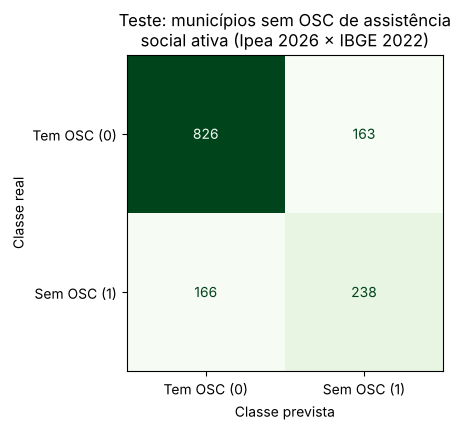

In [6]:
modelo = arvore(prof, folha).fit(X_tr, y_tr)
prev = modelo.predict(X_te)
prev_dummy = ref_dummy.predict(X_te)
prev_regra = (mun_te['populacao_2022'] < L_reg).astype(int).values

def resumo(nome, p):
    cm_ = confusion_matrix(y_te, p, labels=[0, 1]); tn_, fp_, fn_, tp_ = cm_.ravel()
    return {'modelo': nome, 'acuracia': accuracy_score(y_te, p),
            'sensibilidade': recall_score(y_te, p, zero_division=0),
            'precisao': precision_score(y_te, p, zero_division=0),
            'f1': f1_score(y_te, p, zero_division=0), 'TN': tn_, 'FP': fp_, 'FN': fn_, 'TP': tp_}
teste = pd.DataFrame([resumo('Dummy (sempre "tem OSC")', prev_dummy),
                      resumo('Regra pop < %d' % L_reg, prev_regra),
                      resumo('Árvore prof %s / folha %d' % (prof, folha), prev)])
print(teste.round(4).to_string(index=False))

cm = confusion_matrix(y_te, prev, labels=[0, 1]); tn, fp, fn, tp = cm.ravel()
print('\nÁrvore — matriz [linhas reais, colunas previstas]:\n', cm)
print('Acurácia pela matriz: (%d + %d) / %d = %.4f' % (tn, tp, cm.sum(), (tn + tp) / cm.sum()))
print('Sensibilidade classe 1: %d / %d = %.4f' % (tp, tp + fn, tp / (tp + fn)))
print('Precisão classe 1: %d / %d = %.4f' % (tp, tp + fp, tp / (tp + fp)))

fig, ax = plt.subplots(figsize=(5.4, 4.4))
ConfusionMatrixDisplay(cm, display_labels=['Tem OSC (0)', 'Sem OSC (1)']).plot(cmap='Greens', ax=ax, colorbar=False)
ax.set_xlabel('Classe prevista'); ax.set_ylabel('Classe real')
ax.set_title('Teste: municípios sem OSC de assistência\nsocial ativa (Ipea 2026 × IBGE 2022)')
plt.tight_layout(); salvar('pescadores-web-matriz.png'); plt.show()

## 5. O que a árvore aprendeu

|--- log10_pop <= 3.87
|   |--- log10_pop <= 3.59
|   |   |--- reg_Sul <= 0.50
|   |   |   |--- reg_Sudeste <= 0.50
|   |   |   |   |--- weights: [34.00, 180.00] class: 1
|   |   |   |--- reg_Sudeste >  0.50
|   |   |   |   |--- weights: [61.00, 121.00] class: 1
|   |   |--- reg_Sul >  0.50
|   |   |   |--- log10_pop <= 3.29
|   |   |   |   |--- weights: [4.00, 29.00] class: 1
|   |   |   |--- log10_pop >  3.29
|   |   |   |   |--- weights: [95.00, 107.00] class: 1
|   |--- log10_pop >  3.59
|   |   |--- reg_Nordeste <= 0.50
|   |   |   |--- reg_Norte <= 0.50
|   |   |   |   |--- weights: [393.00, 167.00] class: 0
|   |   |   |--- reg_Norte >  0.50
|   |   |   |   |--- weights: [23.00, 31.00] class: 1
|   |   |--- reg_Nordeste >  0.50
|   |   |   |--- log10_pop <= 3.64
|   |   |   |   |--- weights: [10.00, 30.00] class: 1
|   |   |   |--- log10_pop >  3.64
|   |   |   |   |--- weights: [72.00, 134.00] class: 1
|--- log10_pop >  3.87
|   |--- log10_pop <= 4.26
|   |   |--- reg_Nordeste 

figura gravada: ../assets/pescadores-web-arvore.png


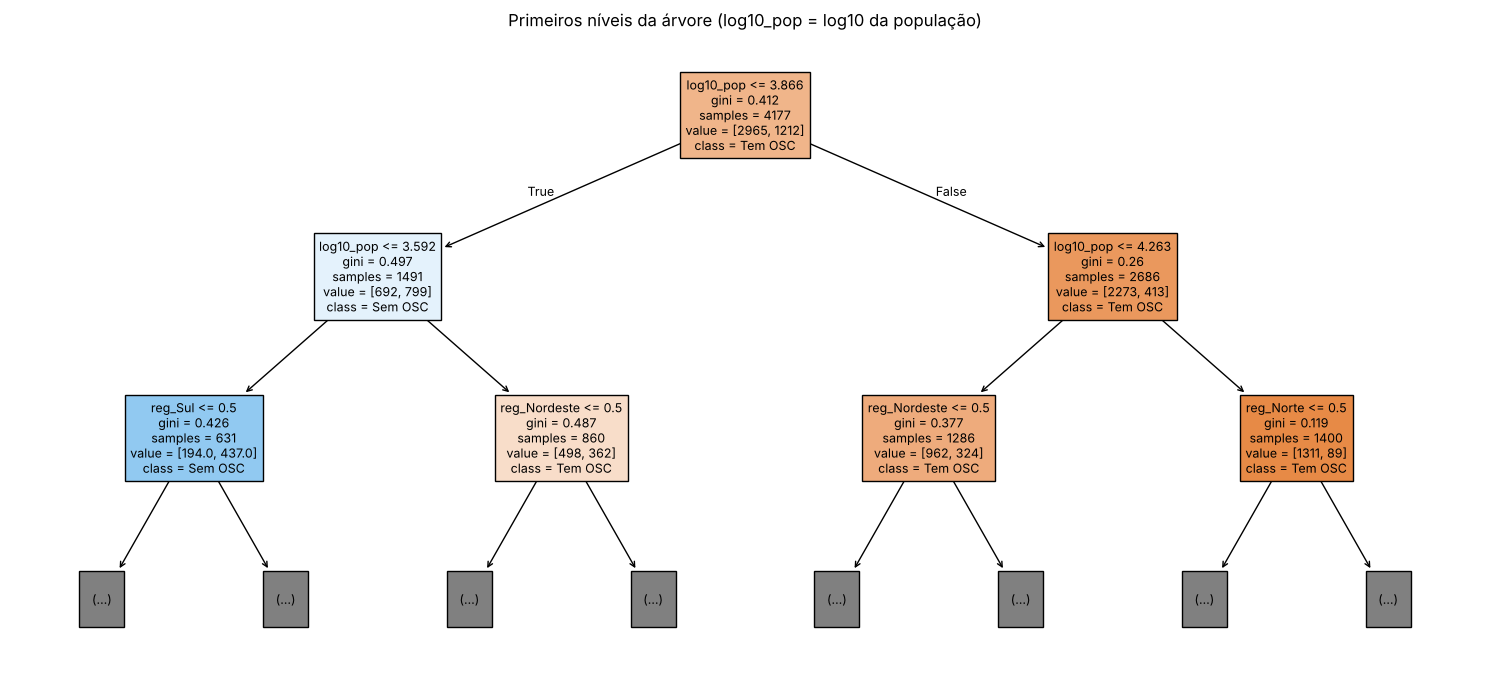

In [7]:
print(export_text(modelo, feature_names=list(X.columns), show_weights=True))
imp = pd.Series(modelo.feature_importances_, index=X.columns).sort_values(ascending=False)
print('Importâncias:', imp.round(3).to_dict())
arv = modelo.tree_
cortes_pop = sorted({round(10 ** arv.threshold[i]) for i in range(arv.node_count)
                     if arv.children_left[i] != -1 and arv.feature[i] == 0})
print('Cortes de população usados pela árvore (habitantes):', cortes_pop)
plt.figure(figsize=(15, 7))
plot_tree(modelo, feature_names=list(X.columns), class_names=['Tem OSC', 'Sem OSC'],
          max_depth=2, filled=True, fontsize=9)
plt.title('Primeiros níveis da árvore (log10_pop = log10 da população)')
plt.tight_layout(); salvar('pescadores-web-arvore.png'); plt.show()

## 6. Erros por porte (teste)
Onde estão os falsos negativos e falsos positivos?

In [8]:
erros = mun_te.assign(previsto=prev)
erros['tipo'] = np.select([(erros.sem_osc_ativa == 1) & (erros.previsto == 0),
                           (erros.sem_osc_ativa == 0) & (erros.previsto == 1)], ['FN', 'FP'], 'acerto')
erros['faixa'] = pd.cut(erros['populacao_2022'], [0, 5_000, 10_000, 20_000, 50_000, 1e8],
                        labels=['até 5 mil', '5–10 mil', '10–20 mil', '20–50 mil', 'acima de 50 mil'])
tab_erros = pd.crosstab(erros['faixa'], erros['tipo'])
print(tab_erros.to_string())
print('\nOSCs ativas nos falsos positivos (municípios previstos "sem OSC" que têm):')
print(erros.loc[erros.tipo == 'FP', 'oscs_ativas'].describe().round(2).to_string())

tipo             FN  FP  acerto
faixa                          
até 5 mil        40  98     216
5–10 mil         38  44     195
10–20 mil        72  16     270
20–50 mil        15   5     224
acima de 50 mil   1   0     159

OSCs ativas nos falsos positivos (municípios previstos "sem OSC" que têm):


count    163.00
mean       1.48
std        1.02
min        1.00
25%        1.00
50%        1.00
75%        2.00
max        8.00


## 7. Experimentos no treino
**A — atributos:** só população × população + região.
**B — generalizar para outra UF:** `GroupKFold` com a UF como grupo (cada validação contém UFs que o modelo não viu), comparado à validação estratificada comum.

In [9]:
cols_pop = ['log10_pop']
expA = []
for nome, cols in [('só população', cols_pop), ('população + região', list(X.columns))]:
    s = cross_validate(arvore(prof, folha), X_tr[cols], y_tr, cv=cv, scoring=METRICAS)
    expA.append({'atributos': nome, 'acc_val': s['test_acc'].mean(), 'rec_val': s['test_rec'].mean(),
                 'f1_val': s['test_f1'].mean(), 'f1_desvio': s['test_f1'].std()})
expA = pd.DataFrame(expA)
print(expA.round(4).to_string(index=False))

gkf = GroupKFold(n_splits=5)
s_g = cross_validate(arvore(prof, folha), X_tr, y_tr, cv=gkf, groups=mun_tr['uf'], scoring=METRICAS)
expB = {'acc_val_grupo_uf': float(s_g['test_acc'].mean()), 'f1_val_grupo_uf': float(s_g['test_f1'].mean()),
        'f1_desvio_grupo_uf': float(s_g['test_f1'].std()), 'rec_val_grupo_uf': float(s_g['test_rec'].mean()),
        'f1_por_dobra': [round(float(v), 4) for v in s_g['test_f1']]}
print('\nGroupKFold por UF:', {k: (round(v, 4) if isinstance(v, float) else v) for k, v in expB.items()})
print('Estratificada comum (escolhida): F1 %.4f ± %.4f' % (esc['f1_val'], esc['f1_desvio']))

         atributos  acc_val  rec_val  f1_val  f1_desvio
      só população   0.7644   0.3803  0.4836     0.0237
população + região   0.7857   0.5950  0.6165     0.0231



GroupKFold por UF: {'acc_val_grupo_uf': 0.7837, 'f1_val_grupo_uf': 0.578, 'f1_desvio_grupo_uf': 0.1004, 'rec_val_grupo_uf': 0.5436, 'f1_por_dobra': [0.4254, 0.5826, 0.5127, 0.6792, 0.6903]}
Estratificada comum (escolhida): F1 0.6165 ± 0.0231


## 8. E o Distrito Federal?

In [10]:
df_linha = mun[mun['uf'] == 'DF'][COLUNAS]
print(df_linha.to_string(index=False))
print('Previsão da árvore para o DF:', modelo.predict(X.loc[df_linha.index])[0],
      '| proporção "sem OSC" na folha: %.3f' % modelo.predict_proba(X.loc[df_linha.index])[0, 1])
co = mun[mun['regiao'] == 'Centro-Oeste']
print('Centro-Oeste: %d municípios, %.1f%% sem OSC ativa no recorte'
      % (len(co), 100 * co['sem_osc_ativa'].mean()))

 cd_municipio     municipio uf  populacao_2022  oscs_ativas
      5300108 Brasília - DF DF         2817381          629
Previsão da árvore para o DF: 0 | proporção "sem OSC" na folha: 0.004
Centro-Oeste: 467 municípios, 32.3% sem OSC ativa no recorte


In [11]:
resultados = {
    'autor': 'Felipe Barbosa Vieira',
    'fonte': 'Ipea Mapa das OSCs (arquivo 20260806, Area_Assistencia_social=1, situação Ativa e não removida) x IBGE Censo 2022 (SIDRA 4714)',
    'n_municipios': int(len(mun)), 'proporcao_sem_osc': float(y.mean()), 'n_sem_osc': int(y.sum()),
    'n_treino': int(len(X_tr)), 'n_teste': int(len(X_te)),
    'profundidade': prof, 'min_samples_leaf': folha,
    'f1_validacao': float(esc['f1_val']), 'f1_desvio_validacao': float(esc['f1_desvio']),
    'acc_validacao': float(esc['acc_val']), 'acc_treino_cv': float(esc['acc_treino']),
    'dummy_acc_validacao': float(s_dummy['test_acc'].mean()),
    'limite_regra_populacao': L_reg,
    'teste': teste.round(4).to_dict(orient='records'),
    'matriz_arvore': cm.tolist(),
    'importancias': {k: float(v) for k, v in imp.items()},
    'grade': grade.round(4).to_dict(orient='records'),
    'erros_por_faixa': {str(k): {str(c): int(v) for c, v in row.items()} for k, row in tab_erros.iterrows()},
    'experimento_atributos': expA.round(4).to_dict(orient='records'),
    'experimento_grupo_uf': expB,
    'df': {'populacao_2022': int(df_linha['populacao_2022'].iloc[0]), 'oscs_ativas': int(df_linha['oscs_ativas'].iloc[0])},
    'centro_oeste_pct_sem_osc': float(100 * co['sem_osc_ativa'].mean()),
    'python': sys.version.split()[0], 'sklearn': sklearn.__version__, 'pandas': pd.__version__,
    'numpy': np.__version__, 'matplotlib': matplotlib.__version__}
with open('resultados_pescadores_web.json', 'w', encoding='utf-8') as f:
    json.dump(resultados, f, ensure_ascii=False, indent=2, default=int)
print('resultados_pescadores_web.json gravado')

resultados_pescadores_web.json gravado


## Interpretação (Felipe)

**Resultado calculado**
- 1.616 dos 5.570 municípios (29,0%) não têm nenhuma OSC de assistência social ativa no recorte. A proporção cai com o porte, de 60,5% até 5 mil habitantes para 0% acima de 100 mil. Também varia por região: 44,0% no Norte e 18,8% no Sudeste.
- A validação no treino escolheu profundidade 4 e folha 10, com F1 de validação de 0,617 ± 0,023 e acurácia de 0,786. A referência `Dummy` ficou em 0,710 de acurácia e F1 zero.
- No teste, a árvore teve acurácia de 0,764, sensibilidade de 0,589 e precisão de 0,594 (TN 826, FP 163, FN 166, TP 238). A **regra de uma linha** "população < 10.500" teve F1 praticamente igual (0,590 contra 0,591), com mais sensibilidade (0,790) e muito menos precisão (0,471).

**Interpretação**
- A árvore supera a referência trivial em acurácia (+5,4 pontos) e é a única das três que equilibra os dois tipos de erro. Ainda assim, **não ganha** de uma regra simples em F1. Para o uso que imagino (orientar onde procurar parceiros), a regra programada já entrega quase o mesmo valor e é mais fácil de explicar. É o tipo de resultado que a Aula 1 pede para levar a sério: ML só se justifica se superar claramente a alternativa sem ML.
- O porte é o atributo dominante (importância 0,71). A região acrescenta informação: sem ela, o F1 de validação cai de 0,617 para 0,484. Nordeste e Norte aparecem nos cortes da árvore.
- Os **falsos positivos** (163) concentram-se em municípios de até 5 mil habitantes e, em mediana, têm **1** OSC ativa. A árvore erra justamente onde existe uma única organização, que é exatamente o parceiro que uma ação social procuraria. Por isso a saída do modelo nunca pode substituir a consulta direta ao Mapa das OSCs.
- Os **falsos negativos** (166) concentram-se entre 10 e 20 mil habitantes: municípios médios em que se esperaria alguma OSC, mas o cadastro não mostra nenhuma.
- **Generalização para UFs não vistas** (`GroupKFold`): o F1 cai para 0,578 e varia muito entre dobras (0,43 a 0,69). As regras aprendidas em alguns estados não valem igualmente para outros, e a validação aleatória comum é otimista para esse uso.
- **DF:** Brasília (2.817.381 habitantes, 629 OSCs ativas) cai numa folha com 0,4% de casos "sem OSC". Para o território onde o Pescadores Web atua, o modelo não acrescenta nada: o que interessa é a lista observada de OSCs, já disponível no projeto.

**Hipótese (não testada):** parte dos "zeros" pode ser falta de cadastro ou de marcação da área "assistência social", e não ausência real de atendimento (CRAS, igrejas e grupos informais, como o próprio Pescadores Web, não aparecem como OSC). Testar isso exigiria cruzar com outras fontes, por exemplo o Censo SUAS.

**Limites:** análise transversal (OSCs em 2026 × população em 2022), sem causalidade. Zero no recorte não prova ausência de assistência social. Os municípios vizinhos não são independentes. É um exercício metodológico que apoia o planejamento, não uma decisão sobre parcerias.

## Fontes
- IPEA. *Mapa das Organizações da Sociedade Civil* — base de dados (arquivo 20260806_MOSC_baseDivulgacao.csv). https://mapaosc.ipea.gov.br/base-dados.
- IBGE. *Censo Demográfico 2022* — SIDRA, tabela 4714, variável 93. https://apisidra.ibge.gov.br/values/t/4714/n6/all/v/93/p/2022.
- VIEIRA, F. B. *Projeto de ciência de dados — perfil e distribuição das OSCs de assistência social* (pasta `Projeto_ciencia_de_dados/` deste repositório).
- SCIKIT-LEARN. *User Guide* (Decision Trees; Cross-validation; GroupKFold). https://scikit-learn.org/stable/user_guide.html.